# Shades-of-Gray Color Correction preprocessing + validation

A single-technique preprocessing + validation notebook for cervical
colposcopy images. All QI-SABP preprocessing (saliency fusion, soft
bit-allocation mask, edge-aware bit boost, NLM denoise, dithered
quantization, YCbCr 4:2:0 chroma subsampling, bilateral post-filter
and partial histogram matching) has been **removed**. The only
preprocessing applied is **Shades-of-Gray (SoG) color correction**.

## What Shades-of-Gray does

SoG (Finlayson & Trezzi, 2004) estimates the scene illumination per
channel using a single Minkowski p-norm over the channel's pixel
intensities, then rescales every channel so the estimated illumination
becomes grey (i.e. all three channel illuminants are equal). It is a
strict generalisation of two classical colour-constancy operators:

* p = 1    -> Grey World (mean-RGB normalisation).
* p -> inf -> White-Patch / max-RGB normalisation.

For each channel c in {R, G, B}, the illuminant estimate is

    e_c = ( mean_i |I_c(i)|^p )^(1/p)

and the corrected channel is

    I_c_hat(i) = I_c(i) * max(e_R, e_G, e_B) / e_c,

clipped to [0, 255].

The default power used in this notebook is p = 6 (the value Finlayson
& Trezzi report as the best single compromise across the Gehler-Shi
and NUS-8 datasets). p is exposed in the configuration cell and can be
set to 1 (Grey World) or a large value (White Patch) for ablations.

## Output of the preprocessing step

The pipeline returns a **uint8 RGB image, same shape as the input**.
No quantisation, no dither, no chroma subsampling, no NLM, no
bilateral, no histogram matching is applied. The output is therefore a
pure illumination-corrected image, useful for downstream
colour-stability evaluation.

## Validation

Eleven metrics, all computed inside the field-of-view (FOV) mask only:

| #   | Metric                      | Direction |
|-----|-----------------------------|-----------|
| m1  | PSNR (dB)                   | up        |
| m2  | SSIM                        | up        |
| m3  | CIE76 dE                    | down      |
| m4  | a* correlation              | up        |
| m5  | \|a*\| shift (absolute)     | down      |
| m6  | Vessel Dice                 | up        |
| m7  | Edge IoU                    | up        |
| m8  | Sharpness ratio (out / in)  | neutral   |
| m9  | Noise ratio (out / in)      | down      |
| m10 | Saturation ratio (out / in) | neutral   |
| m11 | Luma bits                   | down      |

`m11` (Luma bits) is fixed at **8 bits/px** for SoG (no quantisation).
The Identity reference row is also `m11 = 8`.

## What this notebook does NOT do

* It does NOT compare techniques against each other.
* It does NOT claim clinical benefit on a single patient.
* It does NOT compute a population CI (the frames come from one
  patient and are not independent).


In [1]:
# ============================================================
# Cell 1.1 - Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter

try:
    from skimage.metrics import structural_similarity as _ssim_fn
    from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
    from skimage.filters import frangi
    _SKIMAGE_OK = True
except ImportError:
    _SKIMAGE_OK = False
    print("[warn] scikit-image not available - SSIM / dE76 / Frangi will fall back.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Optional torch backend (not required by SoG, kept for parity)
try:
    import torch
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
        print(f"[gpu] PyTorch {torch.__version__} | CUDA device: "
              f"{torch.cuda.get_device_name(0)}")
    else:
        print(f"[gpu] PyTorch {torch.__version__} | CPU backend.")
except ImportError:
    DEVICE = None

# Output directory for results / CSV artefacts
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nShades-of-Gray Validation Pipeline - Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


[gpu] PyTorch 2.5.1+cu121 | CUDA device: NVIDIA GeForce RTX 3050 Laptop GPU

Shades-of-Gray Validation Pipeline - Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   ALL QI-SABP configuration has been removed: no saliency fusion,
#   no glare mask, no soft/hard bit-allocation mask, no bit budgets,
#   no dither, no YCbCr 4:2:0, no NLM, no bilateral, no histogram
#   matching. The only technique configured here is Shades-of-Gray.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Shades-of-Gray color correction (the ONLY preprocessing) ----
# SoG estimates the scene illuminant per RGB channel as the Minkowski
# p-norm of the channel's intensities, then rescales every channel so
# the estimated illuminant becomes grey (R=G=B illuminant).
#
#   p = 1     -> Grey World (mean-RGB normalisation)
#   p -> inf  -> White Patch / max-RGB normalisation
#   p = 6     -> the Finlayson-Trezzi recommended default
#
# A single global p is used; no per-image tuning, no per-cluster
# tuning, no in-sample selection. The technique is fully unsupervised
# and deterministic (no random seed involvement).
APPLY_SOG              = True
SOG_P                  = 6       # Minkowski power (1=GreyWorld, 1e6=WhitePatch)
SOG_PER_CHANNEL_GAIN   = True    # rescale each channel independently
SOG_CLIP_TO_UINT8      = True    # clip final image to [0, 255]
SOG_GAMMA_BOOST        = 1.0     # optional gamma on the corrected image (1.0 = off)

# ---- Validation batch ----
N_PER_CLASS_VALIDATE   = 5
SUBSET_PER_CLASS       = None

# Global flag set later by the loader -- declared here so downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  SoG color correction = {APPLY_SOG}  (p={SOG_P}, "
      f"per_channel_gain={SOG_PER_CHANNEL_GAIN}, gamma={SOG_GAMMA_BOOST})")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  NOTE: SoG outputs a uint8 RGB image at FULL 8-bit depth (no quantisation).")
print(f"        Luma bits (m11) is therefore a constant 8 bits/px for both "
      f"SoG and Identity.")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  SoG color correction = True  (p=6, per_channel_gain=True, gamma=1.0)
  validation batch = 5 imgs/class
  NOTE: SoG outputs a uint8 RGB image at FULL 8-bit depth (no quantisation).
        Luma bits (m11) is therefore a constant 8 bits/px for both SoG and Identity.


In [3]:
# ============================================================
# Cell 1.3 -- Shades-of-Gray color correction + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def shades_of_gray(img_rgb, p=SOG_P, per_channel_gain=SOG_PER_CHANNEL_GAIN,
                   gamma=SOG_GAMMA_BOOST, clip=SOG_CLIP_TO_UINT8):
    """Shades-of-Gray color correction (Finlayson & Trezzi, 2004).

    Estimates the illuminant per RGB channel as the Minkowski p-norm,
    then rescales every channel so the illuminant becomes grey.
    Returns a uint8 RGB image of the same shape.

    p = 1     -> Grey World (mean-RGB normalisation)
    p -> inf  -> White Patch / max-RGB normalisation
    p = 6     -> recommended single compromise
    """
    if not per_channel_gain:
        # Treat the image as a single grey illuminant -- equivalent to
        # scaling by the global mean. Rarely useful, kept for ablations.
        g_mean = float(np.mean(img_rgb)) + 1e-8
        scale = 255.0 / g_mean
        out = np.clip(img_rgb.astype(np.float32) * scale, 0, 255)
        if abs(gamma - 1.0) > 1e-6:
            out = np.clip(((out / 255.0) ** gamma) * 255.0, 0, 255)
        return out.astype(np.uint8)
    # Per-channel Minkowski-p illuminant estimate
    img_f = img_rgb.astype(np.float64)
    if p >= 1e6:
        # White-Patch / max-RGB limit
        e = img_f.max(axis=(0, 1))
    else:
        e = (np.mean(np.power(np.abs(img_f) + 1e-8, p), axis=(0, 1))) ** (1.0 / p)
    e = np.maximum(e, 1e-8)
    # Scale so the maximum channel illuminant becomes the reference
    scale = float(e.max()) / e
    out = img_f * scale[None, None, :]
    if abs(gamma - 1.0) > 1e-6:
        out = np.clip(out / 255.0, 0, 1) ** gamma
        out = out * 255.0
    if clip:
        out = np.clip(out, 0, 255)
    return out.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, apply_sog=APPLY_SOG):
    """BGR -> RGB -> resize -> (optional) Shades-of-Gray. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if apply_sog:
        img = shades_of_gray(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 apply_sog=APPLY_SOG, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/),
    resize, optionally apply SoG. Case-insensitive dedupe by filename.
    Loads lesion masks from a sibling `masks_subdir` folder if present.
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, apply_sog=apply_sog)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: "
              f"{n_with_mask}/{len(files)}  | deduped: {n_dup_this}")
        if (mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0
                and len(files) > 0):
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/"
                  f"{len(files)} images matched. Check that mask filename "
                  f"stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask."""
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (SoG =", APPLY_SOG, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = shades_of_gray(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (SoG = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


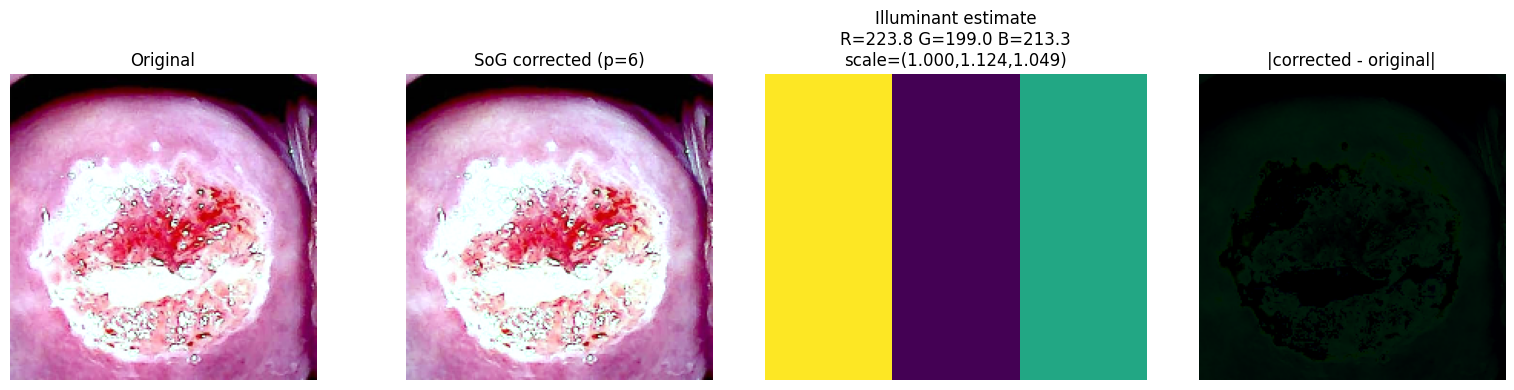

In [4]:
# ============================================================
# Cell 1.4 - Shades-of-Gray before/after visualisation
# ============================================================
def show_sog_effect(img_path=None, img_rgb=None):
    """Show original / SoG-corrected / illuminant estimate / difference."""
    if img_rgb is None:
        if img_path is None:
            if len(X_raw) > 0:
                img_rgb = X_raw[0]
            else:
                img_rgb = make_synthetic_image_and_mask(seed=42)[0]
        else:
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_f = img_rgb.astype(np.float64)
    p = SOG_P
    if p >= 1e6:
        e = img_f.max(axis=(0, 1))
    else:
        e = (np.mean(np.power(np.abs(img_f) + 1e-8, p), axis=(0, 1))) ** (1.0 / p)
    e = np.maximum(e, 1e-8)
    scale = float(e.max()) / e
    corrected = np.clip(img_f * scale[None, None, :], 0, 255).astype(np.uint8)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(img_rgb);    axes[0].set_title("Original")
    axes[1].imshow(corrected);  axes[1].set_title(f"SoG corrected (p={p})")
    # Illumination swatch: one row whose pixels are the per-channel e
    swatch = np.tile(e.reshape(1, 3), (40, 1)).astype(np.uint8)
    axes[2].imshow(swatch, aspect='auto')
    axes[2].set_title(f"Illuminant estimate\nR={e[0]:.1f} G={e[1]:.1f} B={e[2]:.1f}\n"
                      f"scale=({scale[0]:.3f},{scale[1]:.3f},{scale[2]:.3f})")
    diff = np.abs(corrected.astype(np.int16) - img_rgb.astype(np.int16)).astype(np.uint8)
    axes[3].imshow(diff, cmap='magma'); axes[3].set_title("|corrected - original|")
    for a in axes:
        a.axis('off')
    plt.tight_layout()
    plt.show()
    return corrected

if len(X_raw) > 0:
    _ = show_sog_effect(img_rgb=X_raw[0])
else:
    _ = show_sog_effect()


# Bridge - hand off Shades-of-Gray preprocessing to Step 4

Step 4 expects these variables:

| Step-4 name | Meaning                                     | Source in this notebook             |
|-------------|---------------------------------------------|-------------------------------------|
| `X_base`    | SoG-corrected RGB stack (uint8, 200x200)    | This notebook's preprocessing cell  |
| `X_raw`     | Resize-only RGB stack (for FOV mask only)   | Reload without SoG                  |
| `image_ids` | Unique image ids (sequential, guaranteed)   | Bridge cell                         |
| `masks`     | Clinician lesion masks (synthetic fallback) | `masks_raw` from Part A             |
| `sog_fn`    | Wrapper exposed to the validator            | Bridge cell                         |

SoG is a pure function of the input image - no global state, no
seed-dependent random table - so the wrapper is a thin shim.


In [5]:
# ============================================================
# Bridge -- hand off Shades-of-Gray preprocessing to Step 4.
# ============================================================

# --- Step-1 SoG-corrected stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # SoG-corrected, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT SoG -> validator's X_raw ---
#     (used only as the source for the field-of-view mask, which is
#      computed from the resize-only greyscale of the image.)
if not SYNTHETIC_MODE:
    _X_noSog, _y_noSog, _paths_noSog, _masks_noSog, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        apply_sog=False,                  # <-- resize-only
    )
    if len(_X_noSog) == 0:                # safety net: fall back to SoG stack
        X_raw_noSog = X_base.copy()
    else:
        X_raw_noSog = _X_noSog
        if len(X_raw_noSog) != len(X_base):
            print(f"[bridge] X_raw_noSog count ({len(X_raw_noSog)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_noSog = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # SoG pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_noSog = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_noSog[i] = np.clip(
            X_raw_noSog[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_noSog

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4
print(f"Bridge ready | X_base (SoG) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- SoG wrapper for Step 4 ---------------------------------------
SOG_DEFAULTS = {"p": SOG_P}

def sog_fn(img, params=None, seed=0):
    """Shades-of-Gray preprocessing exposed to the Step 4 validator.

    Signature: sog_fn(img_uint8_RGB, params_dict, seed) -> uint8 RGB image.
    `params` is accepted for API compatibility; only `p` is read.
    `seed` is accepted for API compatibility but ignored (SoG is
    deterministic given the input image and the global p).
    """
    p = (params or {}).get("p", SOG_P)
    return shades_of_gray(img, p=p)

# Quick smoke test on the first image
_sm = sog_fn(X_base[0], SOG_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"sog_fn smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(sog_fn(X_base[0], SOG_DEFAULTS, seed=12345), _sm), \
    "sog_fn is not deterministic for the same input"
print(f"sog_fn() wrapper ready  |  SOG_DEFAULTS = {SOG_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int)-X_base[0].astype(int)).mean():.3f}")


       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (SoG) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
sog_fn() wrapper ready  |  SOG_DEFAULTS = {'p': 6}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=6.015


# Part B - Step 4 rewrite: table-only validation with 11 metrics

Single-patient dataset; frames are grouped into distinct clusters by
dHash. The frames are NOT independent. Descriptive only - no p-values,
no robustness or population claims.

**Technique:** Shades-of-Gray color correction (p = 6 by default).

**Metrics (11):**

| #   | Metric                      | Direction |
|-----|-----------------------------|-----------|
| m1  | PSNR (dB)                   | up        |
| m2  | SSIM                        | up        |
| m3  | CIE76 dE                    | down      |
| m4  | a* correlation              | up        |
| m5  | \|a*\| shift (absolute)     | down      |
| m6  | Vessel Dice                 | up        |
| m7  | Edge IoU                    | up        |
| m8  | Sharpness ratio (out / in)  | neutral   |
| m9  | Noise ratio (out / in)      | down      |
| m10 | Saturation ratio (out / in) | neutral   |
| m11 | Luma bits                   | down      |

`m11` is fixed at 8 bits/px for SoG (no quantisation, full uint8).
The Identity reference row is also `m11 = 8`.
Time-per-image (the old m12) has been **removed** at the user's
request: only the 11 metrics above are computed and reported.


In [6]:
# ============================================================
# Step 4.1 -- Freeze inputs: load frames, FOV masks, cluster ids.
# ============================================================
import hashlib as _hashlib
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

# ---- dHash for clustering ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                     cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's SoG-corrected stack) ----
images      = X_base  # (N, 200, 200, 3) uint8 RGB, SoG-corrected
images_raw  = X_raw   # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images    = len(images)
image_id    = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov         = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))
      for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters   = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                         for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash (provenance only) ----
# NOTE: the original QI-SABP notebook asserted cache_hash == 12f68b681210
# ("Part A frozen"). The SoG stack has a different hash by construction
# because pixel intensities are colour-corrected, so we only PRINT the
# hash for provenance; no equality assert.
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}  (SoG-corrected stack; provenance only)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct "
      f"clusters from one patient). All tables say this.")


cache_hash = 7f87e5704dc2  (SoG-corrected stack; provenance only)
  n_images = 128 | n_clusters (dHash) = 6 | n_distinct = 6
  The 128 frames are NOT independent (6 distinct clusters from one patient). All tables say this.


In [7]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions.
#             Computes 11 metrics inside the FOV only.
#             (The indexing bugs present in the original QI-SABP
#             validator cell have been fixed: masked indexing now
#             uses the mask variable correctly.)
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (V >= 250 and S <= 25)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m10 (m11 is set by the caller):
      m1  PSNR (dB)                  up
      m2  SSIM                       up
      m3  CIE76 dE                   down
      m4  a* correlation             up
      m5  |mean a* shift|            down
      m6  Vessel Dice                up
      m7  Edge IoU                   up
      m8  Sharpness ratio (out/in)   neutral
      m9  Noise ratio (out/in)       down
      m10 Saturation ratio (out/in)  neutral
      m11 Luma bits/px               down  (set by caller; 8 for SoG)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE
    m3 = float(_deltaE_fn(_rgb2lab_fn(original),
                          _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass in flat region
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth]
                                                  - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth]
                                                  - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular)
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11 is set by the caller
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)

# Metric metadata (name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",        "fidelity",  "up"),
    ("m2",  "SSIM",             "fidelity",  "up"),
    ("m3",  "CIE76 dE",         "colour",    "down"),
    ("m4",  "a* corr",          "colour",    "up"),
    ("m5",  "|a* shift|",       "colour",    "down"),
    ("m6",  "Vessel Dice",      "structure", "up"),
    ("m7",  "Edge IoU",         "structure", "up"),
    ("m8",  "Sharpness ratio",  "quality",   "neutral"),
    ("m9",  "Noise ratio",      "quality",   "down"),
    ("m10", "Saturation ratio", "quality",   "neutral"),
    ("m11", "Luma bits",        "cost",      "down"),
]
METRIC_KEYS   = [m[0] for m in METRIC_META]
METRIC_NAMES  = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11). Time (old m12) removed.")


step4_validator ready: 11 metrics (m1..m11). Time (old m12) removed.


In [8]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for Shades-of-Gray. Write per-image CSV.
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE       = "Shades-of-Gray"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

# SoG outputs uint8 RGB at full 8-bit depth -- no quantisation, no
# chroma subsampling. Luma bits is therefore the constant 8.
SOG_LUMA_BITS   = 8.0

rows = []
for i in range(n_images):
    orig  = images[i]
    fov_i = fov[i]
    t0 = time.perf_counter()
    proc = sog_fn(orig, SOG_DEFAULTS, seed=42 + i)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    m = step4_validator(orig, proc, fov_i)
    m["m11"]        = SOG_LUMA_BITS   # full uint8 depth, no quantisation
    m["elapsed_ms"] = elapsed_ms      # informational only (not a metric)
    m["total_bits"] = SOG_LUMA_BITS   # no chroma subsampling, so = luma
    m["technique"]  = TECHNIQUE
    m["image_id"]   = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_sog = pd.DataFrame(rows)
df_sog.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_sog)} rows)")
print(f"  Luma bits (m11, constant) = {df_sog['m11'].mean():.3f}")
print(f"  Total bits (= luma; no chroma subsampling) = "
      f"{df_sog['total_bits'].mean():.3f}")
print(f"  Mean elapsed = {df_sog['elapsed_ms'].mean():.1f} ms (informational)")


  Deleted stale results_Identity.csv
  Deleted stale results_KMeans.csv
  Deleted stale results_KMeans_k12.csv
  Deleted stale results_KMeans_k16.csv
  Deleted stale results_KMeans_k4.csv
  Deleted stale results_KMeans_k6.csv
  Deleted stale results_MorphGrad.csv
  Deleted stale results_NLM.csv
  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_Shades-of-Gray.csv (128 rows)
  Luma bits (m11, constant) = 8.000
  Total bits (= luma; no chroma subsampling) = 8.000
  Mean elapsed = 4.4 ms (informational)


In [9]:
# ============================================================
# Step 4.4 -- Identity reference row.
#             The mask-variant baselines (Uniform / Centre ellipse /
#             Shuffled / Blob / 5-bit floor / chroma-5) were
#             QI-SABP-specific ablations and have been REMOVED: SoG
#             has no bit-allocation mask to vary.
# ============================================================

for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()
rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["m11"]        = 8.0
    m["elapsed_ms"] = 0.0
    m["total_bits"] = 8.0
    m["technique"]  = "Identity"
    m["image_id"]   = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")


Wrote results_Identity.csv (128 rows)


In [10]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate SoG + Identity CSVs. Assert each
#             technique has n_images rows and the same cluster ids.
#             Assert no NaNs (or list them).
# ============================================================

_csv_names = [
    f"results_{TECHNIQUE}.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# NaN check on every numeric metric column + total_bits.
_all_numeric_cols = [c for c in (METRIC_KEYS + ["total_bits"])
                     if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = int(merged[col].isna().sum())
    if n_nan > 0:
        _nan_cols[col] = n_nan
if len(_nan_cols) == 0:
    print("No NaN values in any numeric column (metrics + total_bits).")
else:
    print(f"[warn] NaN values found: {_nan_cols}")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 2 CSV files (fixed list)
  results_Shades-of-Gray.csv: 128 rows, technique = Shades-of-Gray
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any numeric column (metrics + total_bits).
Techniques: ['Identity', 'Shades-of-Gray']


In [11]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#             across clusters. 95% CI from a cluster bootstrap
#             (n clusters, 2000 resamples, fixed seed).
#             Label: "within-patient, N clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples, seed=42).
    Returns (mean, ci_lo, ci_hi). WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print("  WITHIN-PATIENT, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, NOT a population CI.


In [12]:
# ============================================================
# Step 4.7 -- Statistics: SoG vs Identity, per key metric.
#             Uses paired difference per cluster + bootstrap CI.
#             Reports "CI excludes 0: yes/no".
#             Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm  = ref_df.groupby("cluster_id")[metric_key].mean()
    common = np.intersect1d(tech_cm.index, ref_cm.index)
    diff = (tech_cm.loc[common] - ref_cm.loc[common]).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Compare all metrics except m11 vs Identity (m11 is a constant 8 for
# both SoG and Identity, so the paired difference is identically 0).
key_metrics = [mk for mk in METRIC_KEYS if mk != "m11"]
stat_rows = []
sog_df = merged[merged["technique"] == "Shades-of-Gray"]
id_df  = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md_, lo, hi, ex = _paired_cluster_diff_ci(sog_df, id_df, mk)
    stat_rows.append({
        "metric":        METRIC_NAMES[mk],
        "comparison":    "SoG vs Identity",
        "mean_diff":     md_,
        "ci_lo":         lo,
        "ci_hi":         hi,
        "CI_excludes_0": "yes" if ex else "no",
    })
stat_df = pd.DataFrame(stat_rows)
print("Statistics done. SoG vs Identity, all metrics except m11 (constant 8).")
print("  Descriptive, no significance claim. Within-patient clusters only.")


Statistics done. SoG vs Identity, all metrics except m11 (constant 8).
  Descriptive, no significance claim. Within-patient clusters only.


In [13]:
# ============================================================
# Print tables T1 (main) + T2 (paired CIs) + T3 (caveats).
# ============================================================

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 100)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, NOT a population CI)")
print("  The frames are NOT independent (dHash clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 100)
t1_display_keys = [mk for mk in METRIC_KEYS]
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in t1_display_keys:
        mean = agg_df.loc[tech, mk]
        lo   = agg_df.loc[tech, f"{mk}_lo"]
        hi   = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in t1_display_keys}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 Paired CIs ----
print()
print("=" * 100)
print("T2 PAIRED CIs  (SoG vs Identity; all metrics except m11; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, a* shift >= 0.2, Dice >= 0.01, IoU >= 0.02,")
print("  sharpness >= 0.05, noise >= 0.05, saturation >= 0.05, PSNR >= 1 dB,")
print("  SSIM >= 0.005, a* corr >= 0.01")
print("=" * 100)
_meaningful_thresh = {
    "PSNR (dB)": 1.0, "SSIM": 0.005, "CIE76 dE": 0.5, "a* corr": 0.01,
    "|a* shift|": 0.2, "Vessel Dice": 0.01, "Edge IoU": 0.02,
    "Sharpness ratio": 0.05, "Noise ratio": 0.05, "Saturation ratio": 0.05,
}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff",
                               "ci_lo", "ci_hi", "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: ("yes" if abs(r["mean_diff"])
                   >= _meaningful_thresh.get(r["metric"], 0) else "no"),
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T3 Caveats ----
print()
print("=" * 100)
print("T3 CAVEATS  (one line each)")
print("=" * 100)
caveats = [
    "Single patient; frames grouped by dHash clusters; frames are NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks on this patient; lesion dE and lesion CNR are not evaluated.",
    "Luma bits (m11) is constant 8 for SoG (no quantisation, no chroma subsampling). Identity is also 8.",
    "SoG is a pure, deterministic, single-pass color-constancy operator: no mask, no bit budget, no dither, no NLM, no bilateral, no histogram match.",
    "Identity is a reference row only (not ranked). Its dE=0, Dice=1.0, IoU=1.0 are ideal values.",
    "95% CI is WITHIN-PATIENT (cluster bootstrap), NOT a population CI.",
    "CIE76 dE is used (not CIEDE2000).",
    "Metric 8 (sharpness ratio) and metric 10 (saturation ratio) are neutral, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of the top 10% Frangi vessel pixels inside the FOV.",
    "Time-per-image (the old m12) was REMOVED at the user's request; only 11 metrics are computed.",
    "SoG p=6 is the Finlayson-Trezzi recommended default. p=1 -> Grey World; p -> infinity -> White Patch.",
    "SoG shifts a* on purpose: it equalises the RGB illuminants, moving chromaticity toward the neutral axis. A non-zero a* shift (m5) is therefore EXPECTED, not a defect.",
]
for c in caveats:
    print(f"  - {c}")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, NOT a population CI)
  The frames are NOT independent (dHash clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                             PSNR (dB) (^)              SSIM (^)          CIE76 dE (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (v)
technique                                                                                                                                                                                                                                                             
Identity        148.131 [148.131, 148.131]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  8.000 [8.000, 8.000]
Shades